# make nonstationary maps

In [2]:
import sys
sys.path.append("../")

from config import *
from figs_config import *

Loaded aesthetics module


In [3]:
import joblib

sphere_mesh = joblib.load(projdir + '/data/fsLR-4k_sphere_grf.pkl')

In [6]:
sphere_mesh.points[:,0].min()

np.float32(-100.0)

In [7]:
def linear_scaling(x0, lims0, lims1):

    x1 = lims1[0] + (np.asarray(x0) - lims0[0]) * (lims1[1] - lims1[0]) / (lims0[1] - lims0[0])
    
    return x1

In [8]:
x = sphere_mesh.points[:, 0]
sigma_i = linear_scaling(x, [-100, 100], [1, 20])

In [10]:
sigma_i.shape

(4002,)

In [52]:
import numpy as np
from scipy.spatial import cKDTree


def gaussian_blur_point_data(mesh, values, sigma_i):
    """
    Blurring of mesh-embedded scalars
    """

    radius = np.max(mesh.points) * 2

    points = np.asarray(mesh.points)
    tree = cKDTree(points)
    neighborhoods = tree.query_ball_point(points, radius)

    smoothed = np.zeros(values.shape)

    # calculate gaussian weighted average
    for i, neighbors in enumerate(neighborhoods):

        sigma = linear_scaling(points[i][0], [-100,100], [1,20])
        print(sigma)

        neighbors = np.asarray(neighbors)
        distances = np.linalg.norm(
            points[neighbors] - points[i],
            axis=1
        )
        weights = np.exp(
            -0.5 * (distances / sigma) ** 2
        )
        weights /= weights.sum()
        smoothed[i] = np.tensordot(
            weights,
            values[neighbors],
            axes=(0, 0)
        )

    return smoothed

In [53]:
import numpy as np

rng = np.random.default_rng(321)
w = rng.normal(loc=0, scale=1, size=4002)

In [54]:
ns = gaussian_blur_point_data(sphere_mesh, w, sigma_i)

18.581182
10.5
2.4188175
10.5
15.494445
5.5055547
5.5055547
15.494445
18.581182
10.5
2.4188175
10.5
18.656136
18.70411
18.725763
18.721712
18.69252
18.6387
18.560707
18.458956
18.333824
18.185661
18.01479
17.821505
17.606077
17.368742
17.10971
16.829144
16.527191
16.203983
15.859666
18.853222
19.095675
19.30881
19.492924
19.648281
19.775108
19.873589
19.943844
19.985966
20.0
19.985966
19.943842
19.873589
19.775108
19.648281
19.492924
19.30881
19.095675
18.853226
15.859666
16.203983
16.527191
16.829144
17.10971
17.368742
17.606077
17.821507
18.01479
18.185661
18.333824
18.458956
18.560705
18.6387
18.69252
18.721712
18.725763
18.70411
18.656136
18.923363
18.965347
18.979897
18.96766
18.92923
18.86512
18.77581
18.66172
18.523232
18.360706
18.174469
17.964823
17.732035
17.476334
17.197908
16.896906
16.573452
16.227655
19.159924
19.194906
19.201366
19.179977
19.13135
19.056015
18.954443
18.827072
18.67429
18.49646
18.293917
18.066957
17.815844
17.540787
17.241959
16.91948
16.573452
19.36615

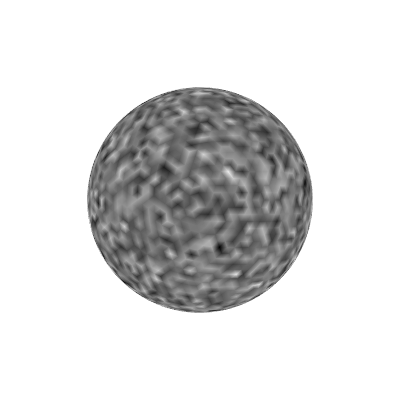

In [65]:
import pyvista as pv

pl = pv.Plotter(window_size = (400, 400))
pl.add_mesh(sphere_mesh.rotate_z(120), scalars=w, cmap = 'binary', **mesh_aes)
pl.camera_position = 'yz'
pl.show(jupyter_backend='static')

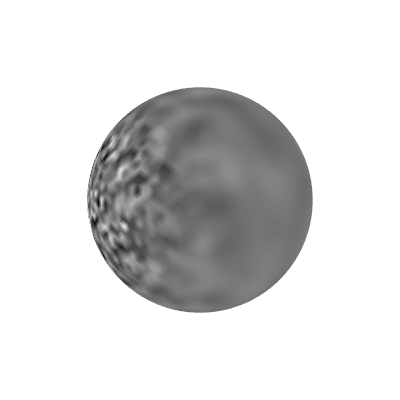

In [64]:
import pyvista as pv

pl = pv.Plotter(window_size = (400, 400))
pl.add_mesh(sphere_mesh.rotate_z(120), scalars=ns, cmap = 'binary', **mesh_aes)
pl.camera_position = 'yz'
pl.show(jupyter_backend='static')